# CNN for patches of 15x15 pixels

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from common.config import (
    MAT_PATH,
    FIGS_DIR,
    TARGET_CLASS_NAMES,
    VALIDATION_FRACTION,
    TEST_FRACTION,
    RANDOM_STATE,
)
from common.utils import NYUDepthV2, make_data_splits, build_patches_dataset, binary_target_mask, extract_patch

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, jaccard_score, roc_auc_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.utils.class_weight import compute_class_weight

import keras
from keras.models import Sequential
from keras.layers import Dense, Activation, Conv2D, MaxPooling2D, Flatten, Dropout

DS_STEP = 20
PATCH_SIZE = 15

In [2]:
nyu = NYUDepthV2(MAT_PATH)
target_ids = [nyu.class_names.index(target) + 1 for target in TARGET_CLASS_NAMES]

In [3]:
# Create train/validation/test image indices
train_indices, val_indices, test_indices = make_data_splits(
    nyu_dataset=nyu,
    validation_fraction=VALIDATION_FRACTION,
    test_fraction=TEST_FRACTION,
    random_state=RANDOM_STATE,
)
print(f"Train images: {len(train_indices)}")
print(f"Validation images: {len(val_indices)}")
print(f"Test images: {len(test_indices)}")

Train images: 1028
Validation images: 206
Test images: 215


In [4]:
X_train, y_train, _ = build_patches_dataset(nyu, train_indices, target_ids,PATCH_SIZE, DS_STEP)
X_test, y_test, _ = build_patches_dataset(nyu, test_indices, target_ids,PATCH_SIZE, DS_STEP)

In [5]:
model = Sequential()
model.add(Conv2D(32, (3, 3), padding='same',
                 input_shape=X_train[0].shape))
model.add(Activation('relu'))
model.add(Conv2D(32, (3, 3)))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(64, (3, 3), padding='same'))
model.add(Activation('relu'))
model.add(Conv2D(64, (3, 3)))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Flatten())
model.add(Dense(512))
model.add(Activation('relu'))
model.add(Dropout(0.5))
model.add(Dense(1))
model.add(Activation('sigmoid'))

/opt/venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1795384095.909231    1863 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [7]:
model.compile(optimizer='adam',
  loss='binary_crossentropy',
  metrics=['accuracy', keras.metrics.AUC(name='auc')])

In [10]:
# Validation set from the validation scenes (not the test set)
X_val, y_val, _ = build_patches_dataset(nyu, val_indices, target_ids, PATCH_SIZE, DS_STEP)

# Balance floor vs not-floor, like class_weight="balanced" in the logistic notebooks
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: weights[0], 1: weights[1]}

early_stop = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                           patience=3, restore_best_weights=True)

history = model.fit(X_train, y_train,
                    epochs=30, batch_size=256,
                    validation_data=(X_val, y_val),
                    class_weight=class_weight,
                    callbacks=[early_stop])

Epoch 1/30
2476/2476 ━━━━━━━━━━━━━━━━━━━━ 165s 59ms/step - accuracy: 0.6230 - auc: 0.7137 - loss: 0.6183 - val_accuracy: 0.6663 - val_auc: 0.7796 - val_loss: 0.6288
Epoch 2/30
2476/2476 ━━━━━━━━━━━━━━━━━━━━ 128s 52ms/step - accuracy: 0.7024 - auc: 0.7866 - loss: 0.5578 - val_accuracy: 0.7690 - val_auc: 0.7945 - val_loss: 0.4729
Epoch 3/30
2476/2476 ━━━━━━━━━━━━━━━━━━━━ 146s 59ms/step - accuracy: 0.7122 - auc: 0.8026 - loss: 0.5407 - val_accuracy: 0.7552 - val_auc: 0.8048 - val_loss: 0.4845
Epoch 4/30
2476/2476 ━━━━━━━━━━━━━━━━━━━━ 148s 60ms/step - accuracy: 0.7213 - auc: 0.8111 - loss: 0.5313 - val_accuracy: 0.7027 - val_auc: 0.8097 - val_loss: 0.5831
Epoch 5/30
2476/2476 ━━━━━━━━━━━━━━━━━━━━ 153s 62ms/step - accuracy: 0.7303 - auc: 0.8186 - loss: 0.5221 - val_accuracy: 0.7183 - val_auc: 0.8248 - val_loss: 0.5366
Epoch 6/30
2476/2476 ━━━━━━━━━━━━━━━━━━━━ 140s 56ms/step - accuracy: 0.7336 - auc: 0.8218 - loss: 0.5181 - val_accuracy: 0.6952 - val_auc: 0.8314 - val_loss: 0.5606
Epoch 7/30

In [11]:
y_proba = model.predict(X_test, batch_size=1024).ravel()
y_pred = (y_proba > 0.5).astype(np.uint8)

print(classification_report(y_test, y_pred, target_names=["not floor", "floor"]))
print(f"floor IoU: {jaccard_score(y_test, y_pred):.3f}")

134/134 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step
              precision    recall  f1-score   support

   not floor       0.97      0.68      0.80    121661
       floor       0.24      0.80      0.37     15299

    accuracy                           0.69    136960
   macro avg       0.60      0.74      0.58    136960
weighted avg       0.88      0.69      0.75    136960

floor IoU: 0.226


AUC:      0.821
Accuracy: 0.692  (baseline 'always not floor': 0.888)
[[82518 39143]
 [ 2990 12309]]


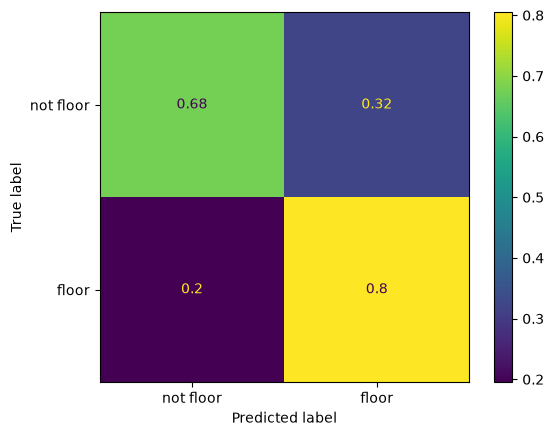

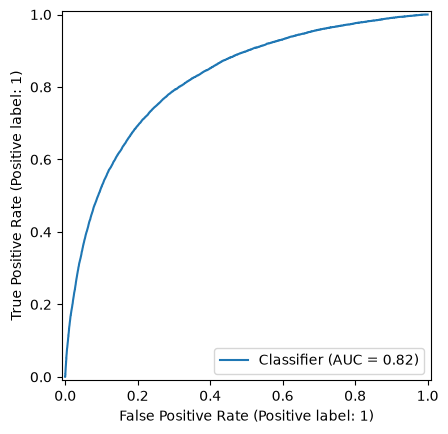

In [12]:
print(f"AUC:      {roc_auc_score(y_test, y_proba):.3f}")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}  (baseline 'always not floor': {1 - y_test.mean():.3f})")
print(confusion_matrix(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true", display_labels=["not floor", "floor"])
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.show()

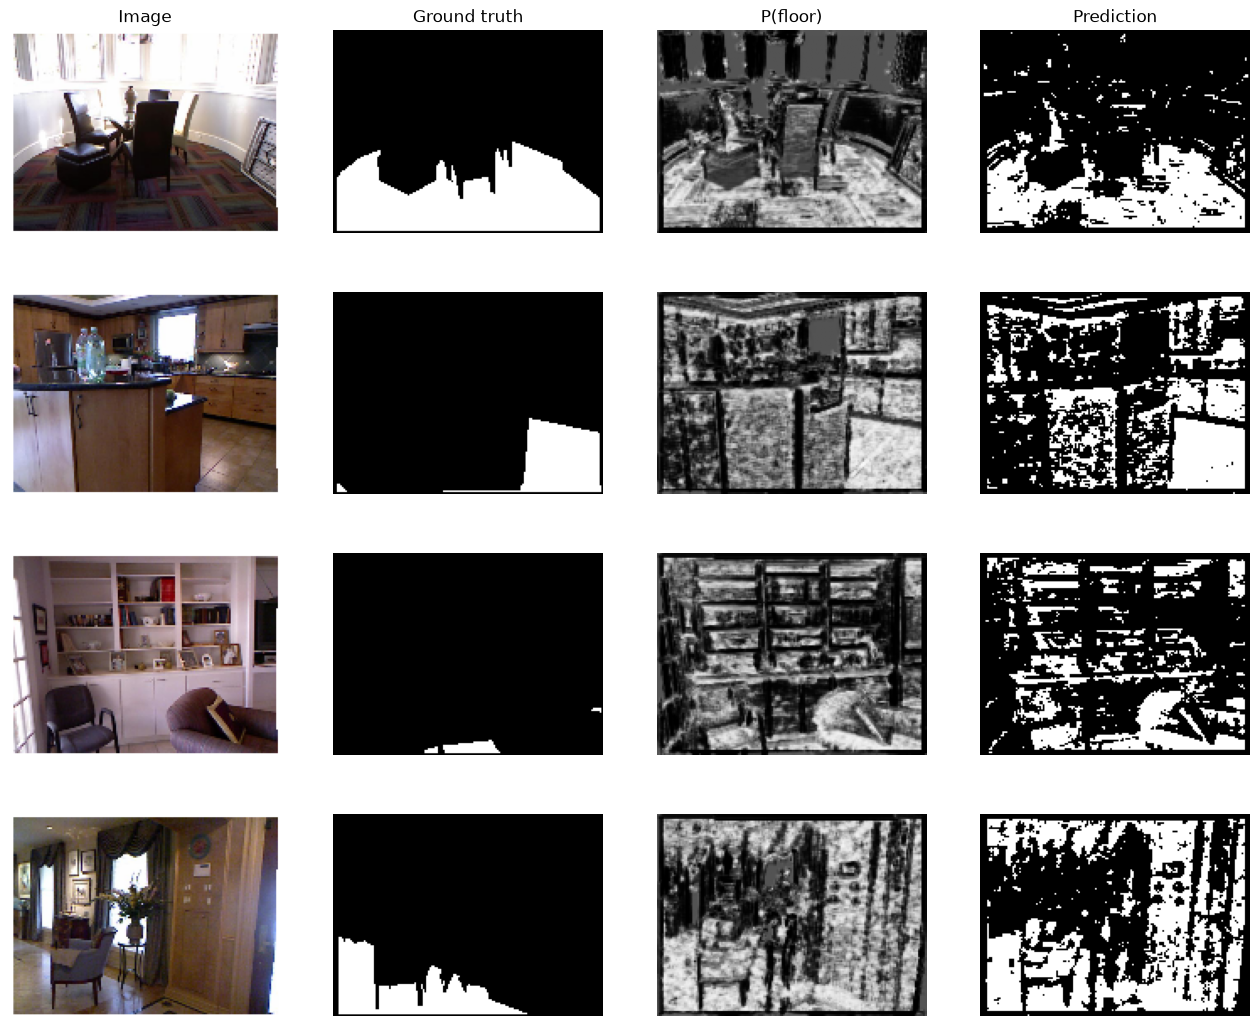

In [15]:
STRIDE = 4   # predict one pixel every 4 (faster)
p = PATCH_SIZE // 2

fig, axes = plt.subplots(4, 4, figsize=(16, 13))

for row, idx in enumerate(test_indices[:4]):
    image, labels = nyu.get_pair(idx)
    gt = binary_target_mask(labels, target_ids)

    # Build one patch for each pixel on the grid
    padded = np.pad(image, ((p, p), (p, p), (0, 0)), mode="edge")
    rows = range(0, image.shape[0], STRIDE)
    cols = range(0, image.shape[1], STRIDE)
    X = np.array([extract_patch(padded, r + p, c + p, PATCH_SIZE) for r in rows for c in cols])
    X = X.astype(np.float32) / 255.0

    # Predict and put back into a (small) image
    proba = model.predict(X, batch_size=2048, verbose=0).reshape(len(rows), len(cols))
    pred = proba > 0.5

    axes[row, 0].imshow(image[::STRIDE, ::STRIDE])
    axes[row, 1].imshow(gt[::STRIDE, ::STRIDE], cmap="gray")
    axes[row, 2].imshow(proba, cmap="gray", vmin=0, vmax=1)
    axes[row, 3].imshow(pred, cmap="gray")

axes[0, 0].set_title("Image")
axes[0, 1].set_title("Ground truth")
axes[0, 2].set_title("P(floor)")
axes[0, 3].set_title("Prediction")

for ax in axes.ravel():
    ax.axis("off")

plt.show()